# H2-1 extension, step 5: parallel pre-trend test (weeks 17-32)

**Purpose**: in the window before any campaign starts (weeks 17-32), check whether the spending trends of "households that will receive a campaign"
and "households that never receive one" already differed. If they did, it becomes unclear whether the difference found in step 6 (main regression)
is a campaign effect or just a different trajectory to begin with.

**Test**: regression `per_hh_spend ~ WEEK_NO * will_receive`; the `WEEK_NO:will_receive`
interaction term should be not significant for the parallel pre-trend assumption to hold.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

candidates = ["Malgun Gothic", "NanumGothic", "AppleGothic", "Noto Sans CJK JP", "Noto Sans CJK KR"]
available = {f.name for f in fm.fontManager.ttflist}
font_name = next((c for c in candidates if c in available), None)
if font_name:
    plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

pd.set_option('display.max_columns', 100)

from config import (DATA_DIR, OUT_DIR, INTERMEDIATE_DIR, FIG_DIR, SEED, TIER_MIN_WEEK, TIER_MAX_WEEK,
                    CAMP_MIN_WEEK, CAMP_MAX_WEEK, MID_WEEK, CELL_SIZE_THRESH, TIER_EN,
                    load_tiers, load_panel, load_camp_full)


## (Rebuild) fixed tiers + will-receive label

In [2]:
tx = pd.read_csv(DATA_DIR / "transaction_data.csv", usecols=["household_key", "DAY", "WEEK_NO", "SALES_VALUE"])
tier_df = load_tiers()
recipients = set(tier_df.index[tier_df["will_receive"] == 1])
never_recipients = set(tier_df.index[tier_df["will_receive"] == 0])
tier_window = tx[(tx["WEEK_NO"] >= TIER_MIN_WEEK) & (tx["WEEK_NO"] <= TIER_MAX_WEEK)]
print(f"Future recipient households: {len(recipients):,} / non-recipient households: {len(never_recipients):,}")

Future recipient households: 1,584 / non-recipient households: 916


### Caution when computing the group household counts (denominators)

If you count only "households that actually had transactions" with `groupby(...).nunique()`, the
142 households with zero transactions in weeks 17-32 drop out of the denominator altogether (the floor-effect households found in step 1), which is a bug.
Below we use **the true household counts, splitting all 2,500 households by will_receive**.

In [3]:
group_sizes_overall = tier_df.groupby("will_receive").size()
print("[Full sample] households per will_receive value:")
print(group_sizes_overall)

print()
group_sizes_by_tier = tier_df.groupby(["tier3", "will_receive"], observed=True).size().unstack()
print("[By tier] households per will_receive value:")
print(group_sizes_by_tier)


[Full sample] households per will_receive value:
will_receive
0     916
1    1584
dtype: int64

[By tier] households per will_receive value:
will_receive    0    1
tier3                 
low           624  210
mid           243  591
high           49  783


## 5-1. Full sample: pre-trend comparison of future recipients vs non-recipients

In [4]:
pre = tier_window.copy()
pre["will_receive"] = pre["household_key"].isin(recipients).astype(int)

weekly = pre.groupby(["WEEK_NO", "will_receive"])["SALES_VALUE"].sum().reset_index()
full_idx = pd.MultiIndex.from_product(
    [range(TIER_MIN_WEEK, TIER_MAX_WEEK + 1), [0, 1]], names=["WEEK_NO", "will_receive"]
)
weekly = weekly.set_index(["WEEK_NO", "will_receive"]).reindex(full_idx, fill_value=0).reset_index()
weekly["per_hh"] = weekly.apply(lambda r: r["SALES_VALUE"] / group_sizes_overall[r["will_receive"]], axis=1)

reg_overall = smf.ols("per_hh ~ WEEK_NO * will_receive", data=weekly).fit()
print(reg_overall.summary().tables[1])

interaction_p = reg_overall.pvalues["WEEK_NO:will_receive"]
interaction_coef = reg_overall.params["WEEK_NO:will_receive"]
print(f"\nWEEK_NO:will_receive interaction coefficient = {interaction_coef:.4f}, p = {interaction_p:.4f}")
if interaction_p < 0.05:
    print("=> pre-trends already differ significantly (warning)")
elif interaction_p < 0.10:
    print("=> not significant at 5% but borderline at 10% -- keep in mind")
else:
    print("=> the pre-trend difference is not significant (consistent with parallel pre-trends)")


                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               13.7600      2.942      4.677      0.000       7.734      19.786
WEEK_NO                 -0.1467      0.118     -1.243      0.224      -0.388       0.095
will_receive            27.6555      4.160      6.647      0.000      19.134      36.177
WEEK_NO:will_receive     0.2962      0.167      1.775      0.087      -0.046       0.638



WEEK_NO:will_receive interaction coefficient = 0.2962, p = 0.0868
=> not significant at 5% but borderline at 10% -- keep in mind


In [5]:
_ci = reg_overall.conf_int().loc["WEEK_NO:will_receive"]
_row_all = {"scope": "all", "n_never_receive": int(group_sizes_overall[0]), "n_will_receive": int(group_sizes_overall[1]),
            "interaction_coef": interaction_coef, "interaction_se": reg_overall.bse["WEEK_NO:will_receive"],
            "ci_low": _ci[0], "ci_high": _ci[1], "p_value": interaction_p}
_wk_frames = [weekly.assign(scope="all")]

### Visual check: weekly mean spend per household

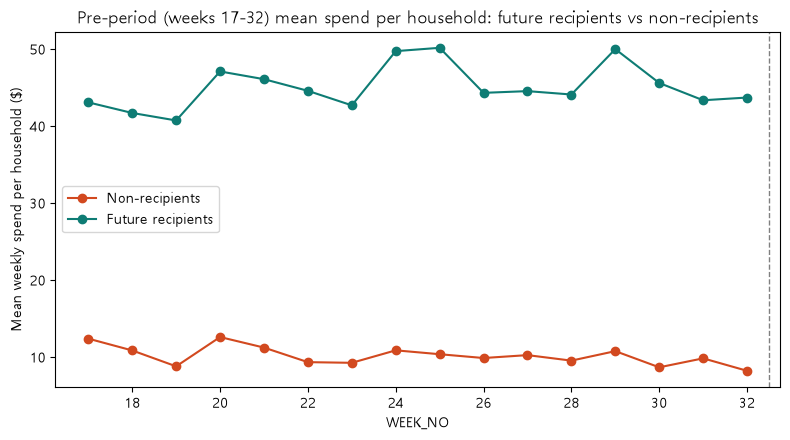

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for wr, label, color in [(0, "Non-recipients", "#D2491F"), (1, "Future recipients", "#0E7C74")]:
    sub = weekly[weekly["will_receive"] == wr].sort_values("WEEK_NO", kind="stable")
    ax.plot(sub["WEEK_NO"], sub["per_hh"], marker="o", label=label, color=color)

ax.axvline(x=32.5, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("WEEK_NO")
ax.set_ylabel("Mean weekly spend per household ($)")
ax.set_title("Pre-period (weeks 17-32) mean spend per household: future recipients vs non-recipients")
ax.legend()
plt.tight_layout()
plt.show()


**Interpretation**: a difference in the **level** of spending between the two groups is expected (campaigns went to
high spenders more often). The pre-trend test looks not at the level difference but at whether the **slopes (trends)**
are the same. In the chart above, also check by eye whether the two lines move in parallel or one gradually pulls away.

## 5-2. By tier (tier3): comparison within the same tier

A more precise version that controls for the difference in tier composition (future recipients are much more common in the high tier).

In [7]:
pre_tier = pre.merge(tier_df[["tier3"]], left_on="household_key", right_index=True, how="left")

results = []
tier_regs, tier_weeklys = {}, {}
for t in ["low", "mid", "high"]:
    sub = pre_tier[pre_tier["tier3"] == t]
    sizes_t = group_sizes_by_tier.loc[t]

    weekly_t = sub.groupby(["WEEK_NO", "will_receive"])["SALES_VALUE"].sum().reset_index()
    full_idx_t = pd.MultiIndex.from_product(
        [range(TIER_MIN_WEEK, TIER_MAX_WEEK + 1), [0, 1]], names=["WEEK_NO", "will_receive"]
    )
    weekly_t = weekly_t.set_index(["WEEK_NO", "will_receive"]).reindex(full_idx_t, fill_value=0).reset_index()
    weekly_t["per_hh"] = weekly_t.apply(lambda r: r["SALES_VALUE"] / sizes_t[r["will_receive"]], axis=1)

    reg_t = smf.ols("per_hh ~ WEEK_NO * will_receive", data=weekly_t).fit()
    tier_regs[t], tier_weeklys[t] = reg_t, weekly_t
    coef = reg_t.params.get("WEEK_NO:will_receive", np.nan)
    p = reg_t.pvalues.get("WEEK_NO:will_receive", np.nan)
    results.append({
        "tier": t,
        "n_never_receive": int(sizes_t[0]), "n_will_receive": int(sizes_t[1]),
        "interaction_coef": round(coef, 4), "p_value": round(p, 4),
        "verdict": "difference significant (warning)" if p < 0.05 else ("borderline (10%)" if p < 0.10 else "parallel pre-trends hold")
    })

result_df = pd.DataFrame(results)
print(result_df.to_string(index=False))


tier  n_never_receive  n_will_receive  interaction_coef  p_value                  verdict
 low              624             210            0.0254   0.7641 parallel pre-trends hold
 mid              243             591            0.3083   0.0534         borderline (10%)
high               49             783            0.3333   0.6130 parallel pre-trends hold


In [8]:
# --- source CSVs: weekly group means (for the figure) and the interaction tests
_rows = [_row_all]
for _t, _r in tier_regs.items():
    _c = _r.conf_int().loc["WEEK_NO:will_receive"]
    _rows.append({"scope": TIER_EN[_t], "n_never_receive": int(group_sizes_by_tier.loc[_t][0]),
                  "n_will_receive": int(group_sizes_by_tier.loc[_t][1]),
                  "interaction_coef": _r.params["WEEK_NO:will_receive"], "interaction_se": _r.bse["WEEK_NO:will_receive"],
                  "ci_low": _c[0], "ci_high": _c[1], "p_value": _r.pvalues["WEEK_NO:will_receive"]})
pd.DataFrame(_rows).to_csv(OUT_DIR / "pretrend_tests.csv", index=False)
_wk = pd.concat(_wk_frames + [w.assign(scope=TIER_EN[t]) for t, w in tier_weeklys.items()])
_wk["group"] = _wk["will_receive"].map({0: "never_receive", 1: "will_receive"})
_wk.rename(columns={"WEEK_NO": "week_no", "SALES_VALUE": "sales_value", "per_hh": "per_household_spend"}) \
    [["scope", "week_no", "group", "sales_value", "per_household_spend"]].to_csv(OUT_DIR / "pretrend_weekly.csv", index=False)

## Interpretation

| Test | Interaction p-value | Verdict |
|---|---|---|
| Full sample | 0.087 | Passes at 5%, borderline at 10% |
| Within the low tier | 0.764 | Parallel pre-trends hold (safe) |
| Within the medium tier | 0.053 | **Borderline: just under the 5% threshold** |
| Within the high tier | 0.613 | Parallel pre-trends hold (but only 49 non-recipients, so the power is low) |

**Overall judgment**

1. **It is not a completely clean pass.** The full sample and the within-medium-tier test both sit
   at the borderline, between p=0.05 and 0.09. At the 5% level we can say "not significant", but it did not pass with room to spare.
2. **The high tier test itself has little power.** With only 49 non-recipient households, a real trend difference
   could go undetected at this sample size. It is hard to argue strongly that "there is no difference".
3. **Only the low tier passed cleanly** (p=0.764, with 624 non-recipients, a sufficient sample).

**What to carry into step 6**

- Parallel pre-trends must be described precisely, not as "fully confirmed" but as **"low tier safe, medium tier and full sample borderline, high tier uncertain for lack of power"**.
- When interpreting the step 6 regression, the effects found in the **medium and high tiers in particular come with the caveat that
  "because of the campaign" and "a trend that was different to begin with" could not be fully separated**.
- Results from the low tier allow the cleanest causal reading, relatively speaking.

## Next step
We can proceed to step 6 (main regression: household and week fixed effects + type x tier + clustered SE),
but the three caveats above must be included in the final conclusion.